<a href="https://colab.research.google.com/github/emilycojo/bigdata-Project1/blob/main/sat5565_proj1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAT5565 Project 1: Bank Marketing Analysis and Spark Performance Scaling
Authored By: Ethan Idalski and Emily Cojocaru

Section 1: Setup

In [ ]:
import os
import sys
import time
import json
import subprocess
from pathlib import Path
from urllib.request import urlopen

import shutil
os.environ["JAVA_HOME"] = str(Path(shutil.which("java")).resolve().parent.parent)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import pyspark
from pyspark.sql import SparkSession

SPARK_HOME = Path(pyspark.__file__).resolve().parent
os.environ["SPARK_HOME"] = str(SPARK_HOME)

CLUSTER_DIR = Path("/content/spark_project_cluster")
CLUSTER_DIR.mkdir(parents=True, exist_ok=True)

cluster_processes = globals().get("cluster_processes", [])

print("PySpark version:", pyspark.__version__)
print("Available CPU cores:", os.cpu_count())
print("Spark installation:", SPARK_HOME)

PySpark version: 4.0.4
Available CPU cores: 2
Spark installation: /usr/local/lib/python3.13/dist-packages/pyspark


In [ ]:
def read_json(url):
    with urlopen(url, timeout=3) as response:
        return json.load(response)

def wait_until(check, description, timeout=120):
    deadline = time.monotonic() + timeout
    last_error = None
    while time.monotonic() < deadline:
        try:
            if check(): return
        except Exception as error:
            last_error = error
        if any(p.poll() is not None for p in cluster_processes):
            raise RuntimeError(f"Spark process exited. Check logs in {CLUSTER_DIR}.")
        time.sleep(1)
    raise RuntimeError(f"Timed out waiting for {description}. Last error: {last_error}. Logs: {CLUSTER_DIR}")

def stop_spark_cluster():
    global spark
    existing = globals().get("spark")
    if existing is not None: existing.stop()
    spark = None
    for process in reversed(cluster_processes):
        if process.poll() is None:
            process.terminate()
            try: process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
    cluster_processes.clear()

def launch_spark_process(name, class_name, *arguments):
    with (CLUSTER_DIR / f"{name}.log").open("w") as log:
        process = subprocess.Popen(
            [str(SPARK_HOME / "bin" / "spark-class"), class_name, *map(str, arguments)],
            env=os.environ.copy(), stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    cluster_processes.append(process)

def active_executors():
    app_id = spark.sparkContext.applicationId
    ui = spark.sparkContext.uiWebUrl
    executors = read_json(f"{ui}/api/v1/applications/{app_id}/executors")
    return [e for e in executors if e["id"] != "driver" and e["isActive"]]

def start_spark_cluster(n_executors):
    global spark
    if n_executors not in (1, 2, 4): raise ValueError("Choose 1, 2, or 4 executors.")
    stop_spark_cluster()
    master_url = "spark://127.0.0.1:7077"
    master_ui = "http://127.0.0.1:18080/json/"
    launch_spark_process("master", "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1", "--port", 7077, "--webui-port", 18080)
    wait_until(lambda: read_json(master_ui)["status"] == "ALIVE", "the Spark master")
    for worker_id in range(n_executors):
        worker_dir = CLUSTER_DIR / f"worker-{worker_id}"
        worker_dir.mkdir(exist_ok=True)
        launch_spark_process(f"worker-{worker_id}", "org.apache.spark.deploy.worker.Worker",
            "--host", "127.0.0.1", "--port", 7100 + worker_id,
            "--webui-port", 18081 + worker_id, "--cores", 1, "--memory", "1g",
            "--work-dir", worker_dir, master_url)
    wait_until(lambda: sum(w["state"] == "ALIVE" for w in read_json(master_ui)["workers"]) == n_executors,
        f"{n_executors} workers")
    spark = (SparkSession.builder.master(master_url).appName(f"Project-{n_executors}-Executors")
        .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")
        .config("spark.executor.cores", "1").config("spark.executor.memory", "1g")
        .config("spark.cores.max", str(n_executors)).config("spark.dynamicAllocation.enabled", "false")
        .config("spark.sql.shuffle.partitions", "8").config("spark.default.parallelism", "8")
        .config("spark.sql.adaptive.enabled", "false").getOrCreate())
    spark.sparkContext.setLogLevel("WARN")
    wait_until(lambda: len(active_executors()) == n_executors, f"{n_executors} active executors")
    print("Spark version:", spark.version)
    print("Master:", spark.sparkContext.master)
    print("Active executors:", len(active_executors()))
    print("Cores per executor: 1")
    return spark


In [ ]:
spark = start_spark_cluster(1)

# **SAMPLE TEST**

df = spark.createDataFrame(
    [("Alice", 25), ("Bob", 30)],
    ["name", "age"],
)
df.show()

test_df = spark.range(0, 100_000, numPartitions=8)

print("Test record count:", test_df.count())
print("Partitions:", test_df.rdd.getNumPartitions())

for executor in active_executors():
    print(
        "Executor:", executor["id"],
        "| Cores:", executor["totalCores"],
        "| Active:", executor["isActive"],
    )

Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 1
Cores per executor: 1
+-----+---+
| name|age|
+-----+---+
|Alice| 25|
|  Bob| 30|
+-----+---+

Test record count: 100000
Partitions: 8
Executor: 0 | Cores: 1 | Active: True


In [ ]:
N_EXECUTORS = 2

spark = start_spark_cluster(N_EXECUTORS)


Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 2
Cores per executor: 1


Section 2: Importing dataset

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile

DATA_DIR = Path("/content/bank_marketing")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_DIR / "bank.zip"
DATA_PATH = DATA_DIR / "bank-full.csv"

if not DATA_PATH.exists():
    urlretrieve(
        "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
        DATA_DIR / "bank_marketing.zip",
    )

    # UCI packages bank-full.csv inside a second ZIP file.
    with zipfile.ZipFile(DATA_DIR / "bank_marketing.zip") as outer:
        with outer.open("bank.zip") as source:
            ZIP_PATH.write_bytes(source.read())

    with zipfile.ZipFile(ZIP_PATH) as inner:
        DATA_PATH.write_bytes(inner.read("bank-full.csv"))

print("Dataset ready:", DATA_PATH)

Dataset ready: /content/bank_marketing/bank-full.csv


In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType
)

numeric_columns = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous",
]

column_names = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "duration", "campaign", "pdays",
    "previous", "poutcome", "y",
]

schema = StructType([
    StructField(
        name,
        IntegerType() if name in numeric_columns else StringType(),
        True,
    )
    for name in column_names
])

original_df = (
    spark.read
    .option("header", "true")
    .option("sep", ";")
    .option("mode", "FAILFAST")
    .schema(schema)
    .csv(str(DATA_PATH))
    .withColumn("source_id", F.monotonically_increasing_id())
    .cache()
)

original_count = original_df.count()
assert original_count == 45_211, original_count

def replicate_twice(data):
    return (
        data.withColumn("replica", F.lit(0))
        .unionByName(data.withColumn("replica", F.lit(1)))
        .repartition(8)
    )

df = replicate_twice(original_df)

print(f"Original records: {original_count:,}")
print(f"Records after replication: {df.count():,}")

df.select(
    "age", "job", "balance", "campaign", "y"
).show(10)

Original records: 45,211
Records after replication: 90,422
+---+----------+-------+--------+---+
|age|       job|balance|campaign|  y|
+---+----------+-------+--------+---+
| 57|management|   3381|       1| no|
| 49|technician|    874|       2| no|
| 31|management|   1260|       1| no|
| 58|technician|   4299|       3| no|
| 42|technician|    -15|       1| no|
| 30| housemaid|    113|       3| no|
| 37|technician|   2139|       3| no|
| 40|technician|    657|       2| no|
| 35| housemaid|    745|       3|yes|
| 32|management|     20|       2|yes|
+---+----------+-------+--------+---+
only showing top 10 rows


Section 3: Logistic Classification using PySpark MLlib (Emily)

In [ ]:
import time
import numpy as np
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# 1. Pipeline setup & evaluators
categorical_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
# Drop duration (not available before call)
numeric_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="skip") for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_vec") for c in categorical_cols]
label_indexer = StringIndexer(inputCol="y", outputCol="label")

feature_cols = numeric_cols + [f"{c}_vec" for c in categorical_cols]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=20)
pipeline = Pipeline(stages=indexers + encoders + [label_indexer, assembler, lr])

eval_roc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
eval_f1 = MulticlassClassificationEvaluator(labelCol="label", metricName="f1")

# 2. Benchmark loop (1, 2, and 4 executors)
emily_results = []
t1_mean = None

for n_exec in [1, 2, 4]:
    print(f"\n==================================================")
    print(f"  EMILY'S BENCHMARK: {n_exec} Executor(s)")
    print(f"==================================================")

    # Launch cluster configuration
    spark = start_spark_cluster(n_exec)

    # Re-read raw data under active SparkSession to prevent session disconnect errors
    orig_df = (
        spark.read
        .option("header", "true")
        .option("sep", ";")
        .option("mode", "FAILFAST")
        .schema(schema)
        .csv(str(DATA_PATH))
        .withColumn("source_id", F.monotonically_increasing_id())
    )

    # Split before replication to avoid leakage
    train_orig, test_orig = orig_df.randomSplit([0.8, 0.2], seed=42)
    train_df = replicate_twice(train_orig).cache()
    test_df = replicate_twice(test_orig).cache()

    # Materialize cache
    train_df.count()
    test_df.count()

    # Untimed warm-up
    print("Running untimed warm-up...")
    warmup_model = pipeline.fit(train_df)
    _ = warmup_model.transform(test_df).count()

    # 3 timed repeats
    runtimes = []
    roc_auc, f1_score = 0.0, 0.0

    for run in range(1, 4):
        start = time.time()

        model = pipeline.fit(train_df)
        preds = model.transform(test_df)

        roc_auc = eval_roc.evaluate(preds)
        f1_score = eval_f1.evaluate(preds)

        elapsed = time.time() - start
        runtimes.append(elapsed)
        print(f"  Run {run}: {elapsed:.2f}s")

    mean_t = float(np.mean(runtimes))
    std_t = float(np.std(runtimes))

    if n_exec == 1:
        t1_mean = mean_t
    speedup = t1_mean / mean_t

    emily_results.append({
        "executors": n_exec,
        "mean_time": mean_t,
        "std_time": std_t,
        "speedup": speedup,
        "auc": roc_auc,
        "f1": f1_score
    })

# 3. Results summary
print("\n" + "="*70)
print("  LOGISTIC CLASSIFICATION PERFORMANCE SUMMARY  ")
print("="*70)
print(f"{'Execs':<6} | {'Mean Time (s)':<15} | {'Std Dev (s)':<12} | {'Speedup':<10} | {'ROC-AUC':<9} | {'F1':<9}")
print("-" * 70)
for r in emily_results:
    print(f"{r['executors']:<6} | {r['mean_time']:<15.2f} | {r['std_time']:<12.2f} | {r['speedup']:<10.2f}x | {r['auc']:<9.4f} | {r['f1']:<9.4f}")


  EMILY'S BENCHMARK: 1 Executor(s)
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 1
Cores per executor: 1
Running untimed warm-up...
  Run 1: 34.13s
  Run 2: 24.74s
  Run 3: 22.08s

  EMILY'S BENCHMARK: 2 Executor(s)
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 2
Cores per executor: 1
Running untimed warm-up...
  Run 1: 37.16s
  Run 2: 31.22s
  Run 3: 29.66s

  EMILY'S BENCHMARK: 4 Executor(s)
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 4
Cores per executor: 1
Running untimed warm-up...
  Run 1: 53.94s
  Run 2: 39.11s
  Run 3: 35.04s

  LOGISTIC CLASSIFICATION PERFORMANCE SUMMARY  
Execs  | Mean Time (s)   | Std Dev (s)  | Speedup    | ROC-AUC   | F1       
----------------------------------------------------------------------
1      | 26.98           | 5.17         | 1.00      x | 0.7678    | 0.8635   
2      | 32.68           | 3.23         | 0.83      x | 0.7678    | 0.8635   
4      | 42.70           | 8.12 

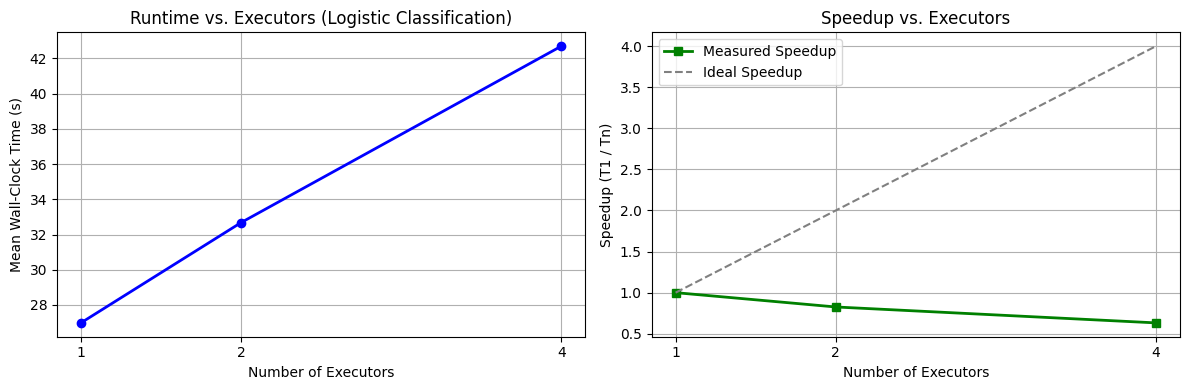

In [ ]:
import matplotlib.pyplot as plt

exec_counts = [r["executors"] for r in emily_results]
mean_times = [r["mean_time"] for r in emily_results]
speedups = [r["speedup"] for r in emily_results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Mean Runtime
ax1.plot(exec_counts, mean_times, marker='o', color='b', linewidth=2)
ax1.set_xlabel('Number of Executors')
ax1.set_ylabel('Mean Wall-Clock Time (s)')
ax1.set_title('Runtime vs. Executors (Logistic Classification)')
ax1.set_xticks([1, 2, 4])
ax1.grid(True)

# Plot 2: Speedup Curve vs. Ideal
ax2.plot(exec_counts, speedups, marker='s', color='g', linewidth=2, label='Measured Speedup')
ax2.plot(exec_counts, exec_counts, linestyle='--', color='gray', label='Ideal Speedup')
ax2.set_xlabel('Number of Executors')
ax2.set_ylabel('Speedup (T1 / Tn)')
ax2.set_title('Speedup vs. Executors')
ax2.set_xticks([1, 2, 4])
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig('logistic_classification_scaling.png')
plt.show()

Section 4: Correlation analysis (Ethan)

In [ ]:
import os
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

correlation_cols = ["age", "balance", "campaign", "previous"]
OUTPUT_DIR = Path("/content/project_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def run_correlation_job(executors):
    """Start Spark, prepare the bank data, and return a completed matrix."""
    global spark
    spark = start_spark_cluster(executors)
    assert len(active_executors()) == executors

    # Read the original 45,211 records using the shared schema.
    bank = (spark.read.option("header", "true").option("sep", ";")
            .option("mode", "FAILFAST").schema(schema).csv(str(DATA_PATH)))
    assert bank.count() == 45_211

    # Make two copies, keep four numerical columns, and prepare Spark vectors.
    numbers = replicate_twice(bank).select([
        F.col(c).cast("double").alias(c) for c in correlation_cols
    ]).na.drop(subset=correlation_cols)
    assembler = VectorAssembler(inputCols=correlation_cols, outputCol="features")
    features = assembler.transform(numbers).select("features")
    assert features.count() == 90_422
    assert features.rdd.getNumPartitions() == 8

    return Correlation.corr(features, "features", "pearson").first()[0].toArray()


In [ ]:
print("CPUs:", os.cpu_count())
print("RAM (GiB):", round(psutil.virtual_memory().total / 1024**3, 2))
print("8 partitions; 1 core and 1 GB per executor")

ethan_runs = []
ethan_results = []
correlation_matrices = {}

for executors in [1, 2, 4]:
    times = []
    print(f"\nTesting {executors} executor(s)")

    for repeat in [1, 2, 3]:
        stop_spark_cluster()
        start = time.perf_counter()
        matrix = run_correlation_job(executors)
        seconds = time.perf_counter() - start

        if correlation_matrices:
            np.testing.assert_allclose(matrix, correlation_matrices[1], atol=1e-8, rtol=1e-8)
        correlation_matrices[executors] = matrix
        times.append(seconds)
        ethan_runs.append({"executors": executors, "run": repeat, "runtime_seconds": seconds})
        print(f"Run {repeat}: {seconds:.2f} seconds; 90,422 records; 8 partitions")
        pd.DataFrame(ethan_runs).to_csv(OUTPUT_DIR / "ethan_correlation_runs.csv", index=False)

    mean_time = float(np.mean(times))
    if executors == 1:
        baseline = mean_time
    ethan_results.append({
        "executors": executors,
        "mean_time": mean_time,
        "std_time": float(np.std(times)),
        "speedup": baseline / mean_time,
    })
    pd.DataFrame(ethan_results).to_csv(OUTPUT_DIR / "ethan_correlation_summary.csv", index=False)

print("\nFull-run timings: startup + loading + preparation + correlation")
display(pd.DataFrame(ethan_results).round(4))


CPUs: 2
RAM (GiB): 12.67
8 partitions; 1 core and 1 GB per executor

Testing 1 executor(s)
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 1
Cores per executor: 1
Run 1: 34.89 seconds; 90,422 records; 8 partitions
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 1
Cores per executor: 1
Run 2: 32.89 seconds; 90,422 records; 8 partitions
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 1
Cores per executor: 1
Run 3: 34.62 seconds; 90,422 records; 8 partitions

Testing 2 executor(s)
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 2
Cores per executor: 1
Run 1: 55.60 seconds; 90,422 records; 8 partitions
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 2
Cores per executor: 1
Run 2: 54.11 seconds; 90,422 records; 8 partitions
Spark version: 4.0.4
Master: spark://127.0.0.1:7077
Active executors: 2
Cores per executor: 1
Run 3: 55.09 seconds; 90,422 records; 8 partitions

Testing 4 execu

,executors,mean_time,std_time,speedup
0,1,34.1355,0.8850,1.0000
1,2,54.9356,0.6192,0.6214
2,4,96.6931,1.2508,0.3530


,age,balance,campaign,previous
age,1.0000,0.0978,0.0048,0.0013
balance,0.0978,1.0000,-0.0146,0.0167
campaign,0.0048,-0.0146,1.0000,-0.0329
previous,0.0013,0.0167,-0.0329,1.0000


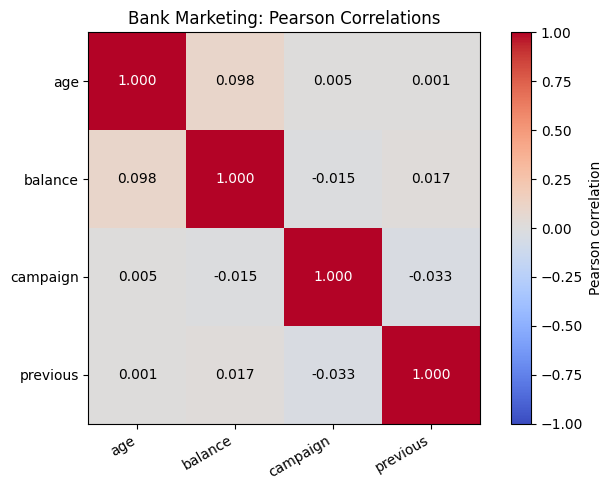

,variable_1,variable_2,correlation,absolute_correlation
0,age,balance,0.0978,0.0978
5,campaign,previous,-0.0329,0.0329
4,balance,previous,0.0167,0.0167
3,balance,campaign,-0.0146,0.0146
1,age,campaign,0.0048,0.0048
2,age,previous,0.0013,0.0013


In [ ]:
matrix = correlation_matrices[1]

correlation_table = pd.DataFrame(
    matrix,
    index=correlation_cols,
    columns=correlation_cols,
)

display(correlation_table.round(4))

correlation_table.to_csv(
    OUTPUT_DIR / "bank_correlation_matrix.csv"
)

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_cols)))
ax.set_yticks(range(len(correlation_cols)))
ax.set_xticklabels(correlation_cols, rotation=30, ha="right")
ax.set_yticklabels(correlation_cols)
ax.set_title("Bank Marketing: Pearson Correlations")

for i in range(len(correlation_cols)):
    for j in range(len(correlation_cols)):
        ax.text(
            j, i, f"{matrix[i, j]:.3f}",
            ha="center", va="center",
            color="white" if abs(matrix[i, j]) > 0.6 else "black",
        )

fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "bank_correlation_heatmap.png",
    dpi=200, bbox_inches="tight",
)
plt.show()

pairs = [
    {
        "variable_1": correlation_cols[i],
        "variable_2": correlation_cols[j],
        "correlation": matrix[i, j],
    }
    for i in range(len(correlation_cols))
    for j in range(i + 1, len(correlation_cols))
]

pair_table = pd.DataFrame(pairs)
pair_table["absolute_correlation"] = pair_table["correlation"].abs()

display(
    pair_table.sort_values(
        "absolute_correlation", ascending=False
    ).round(4)
)

Section 5: Comparison

Timing note: Ethan includes startup, loading, preparation and correlation. Emily measures fitting and evaluation on prepared data. The scopes differ.


,member,method,executors,mean_time,std_time,speedup
0,Ethan,Correlation,1,34.1355,0.8850,1.0000
1,Ethan,Correlation,2,54.9356,0.6192,0.6214
2,Ethan,Correlation,4,96.6931,1.2508,0.3530
3,Emily,Logistic classification,1,26.9832,5.1668,1.0000
4,Emily,Logistic classification,2,32.6779,3.2311,0.8257
5,Emily,Logistic classification,4,42.6962,8.1188,0.6320


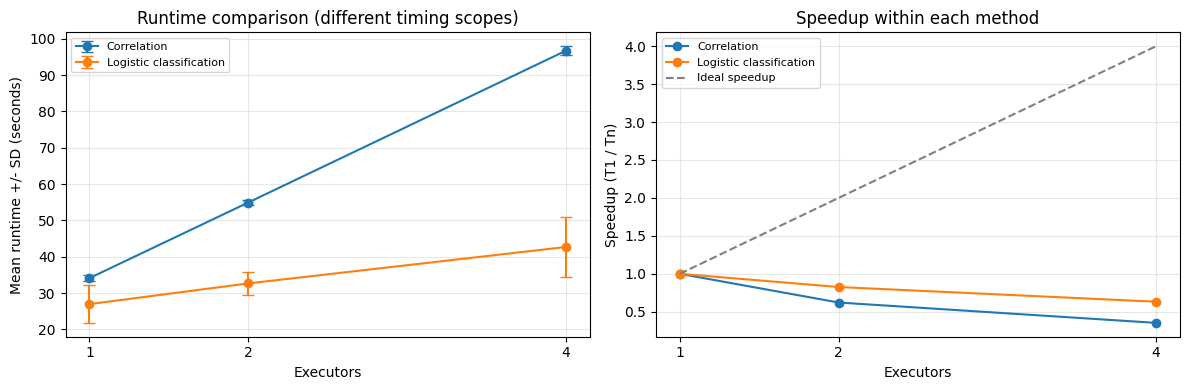

In [ ]:
# Combine both members' summaries
ethan_table = pd.DataFrame(ethan_results).assign(member="Ethan", method="Correlation")
emily_table = pd.DataFrame(emily_results).assign(member="Emily", method="Logistic classification")
columns = ["member", "method", "executors", "mean_time", "std_time", "speedup"]
combined_results = pd.concat([ethan_table[columns], emily_table[columns]], ignore_index=True)

display(combined_results.round(4))
combined_results.to_csv(OUTPUT_DIR / "team_scaling_comparison.csv", index=False)
pd.DataFrame(emily_results).to_csv(OUTPUT_DIR / "emily_logistic_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, results in combined_results.groupby("method"):
    results = results.sort_values("executors")
    axes[0].errorbar(results.executors, results.mean_time, yerr=results.std_time,
                     marker="o", capsize=4, label=method)
    axes[1].plot(results.executors, results.speedup, marker="o", label=method)

axes[0].set(title="Runtime comparison (different timing scopes)", ylabel="Mean runtime +/- SD (seconds)")
axes[1].set(title="Speedup within each method", ylabel="Speedup (T1 / Tn)")
axes[1].plot([1, 2, 4], [1, 2, 4], "--", color="gray", label="Ideal speedup")
for ax in axes:
    ax.set_xlabel("Executors")
    ax.set_xticks([1, 2, 4])
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "team_scaling_comparison.png", dpi=200)
plt.show()
